In [1]:
from selenium import webdriver
from selenium.webdriver.support.wait import WebDriverWait
from selenium.webdriver.support import expected_conditions
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.support.ui import Select

import pandas as pd
pd.options.display.max_columns=100
import pickle
import os
import sys
import warnings
import time

from bs4 import BeautifulSoup
import requests
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'}
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36", "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8", "Accept-Language": "en-US,en;q=0.9", "Referer": "https://www.ewg.org/tapwater/", "Connection": "keep-alive"}



from selenium.webdriver.edge.options import Options

edge_options = Options()
#edge_options.add_argument('--headless')
edge_options.add_argument("--disable-images")  # Disable images
edge_options.add_argument("--disable-javascript")  # Disable JavaScript
edge_options.add_argument("--disable-plugins")  # Disable plugins
edge_options.add_argument("--disable-extensions")  # Disable extensions
edge_options.add_argument("--blink-settings=imagesEnabled=false")  # Another image disabling flag


# Set a minimal User-Agent (like a text-only browser)
edge_options.add_argument("user-agent=Links (2.25; Linux 2.4.24)")

driver = webdriver.Edge(options=edge_options)
#driver.execute_cdp_cmd("Network.setBlockedURLs", {"urls": ["*.jpg", "*.png", "*.gif","*.svg"]})
#driver.execute_cdp_cmd("Network.enable", {})


driver.maximize_window()

driver.execute_script("document.body.style.zoom='67%'")

driver.quit()

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

In [ ]:
import warnings
warnings.filterwarnings('ignore')

### Scraping

In [ ]:
url='http://ufcstats.com/statistics/events/completed?page=all'
driver.get(url)
time.sleep(2)

In [ ]:
event_urls=[e.get_attribute('href') for e in driver.find_elements(By.CSS_SELECTOR, 'tbody tr[class="b-statistics__table-row"] a')]
len(event_urls)

In [ ]:
df=pd.DataFrame()

for i, event_url in enumerate(event_urls, start=1):
    driver.get(event_url)
    WebDriverWait(driver, 10).until(expected_conditions.presence_of_element_located((By.CSS_SELECTOR, 'table.b-fight-details__table tbody tr')))

    html = driver.page_source
    soup = BeautifulSoup(html, 'html.parser')

    try:
        event=soup.select_one('span[class="b-content__title-highlight"]').text.replace('\n','').strip()
    except:
        event=None
        
    try:
        date=soup.select_one('div[class="b-list__info-box b-list__info-box_style_large-width"] ul li:nth-child(1)').text.replace('\n','').strip().split('Date:')[-1].strip()
    except:
        date=None
        

    
    rows = soup.select('tbody tr')
    dicts_ = []
    for row in rows:
        links = row.select('td p a.b-link')
        dicts_.append({
            'fighter_1': links[0]['href'],
            'fighter_2': links[1]['href']
        })
    
    table = pd.read_html(html)[0]
    table = pd.concat([table, pd.DataFrame(dicts_)], axis=1)
    table['event']=event
    table['date']=date

    df=pd.concat([df, table], ignore_index=True)

    print(f'{i}/{len(event_urls)}', end='\r')

In [ ]:
df.to_csv('UFC all events.csv', index=False)

In [3]:
df=pd.read_csv('UFC all events.csv')
df

,W/L,Fighter,Kd,Str,Td,Sub,Weight class,Method,Round,Time,fighter_1,fighter_2,event,date
0,win,Mike Malott Joaquin Buckley,1 0,37 14,0 0,0 0,Welterweight,KO/TKO Knee,2,2:32,http://ufcstats.com/fighter-details/dd6103dd71...,http://ufcstats.com/fighter-details/b943760049...,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
1,win,Jasmine Jasudavicius Erin Blanchfield,0 0,43 62,5 1,3 0,Women's Flyweight,U-DEC,3,5:00,http://ufcstats.com/fighter-details/a9e260472d...,http://ufcstats.com/fighter-details/669970f7fe...,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
2,win,Cristian Perez Kyle Nelson,1 0,10 5,0 0,0 0,Lightweight,KO/TKO Punches,1,0:27,http://ufcstats.com/fighter-details/d840331577...,http://ufcstats.com/fighter-details/31f8081c76...,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
3,win,Marc-Andre Barriault Kyle Daukaus,1 0,32 5,0 1,0 0,Middleweight,KO/TKO Elbows,1,4:28,http://ufcstats.com/fighter-details/8e9eb3fc86...,http://ufcstats.com/fighter-details/d6c0cdd7e4...,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
4,win,Timmy Cuamba Louis Jourdain,0 0,22 9,4 0,1 1,Bantamweight,SUB Neck Crank,2,2:48,http://ufcstats.com/fighter-details/0e46690e55...,http://ufcstats.com/fighter-details/91cd52cb92...,UFC Fight Night: Buckley vs. Malott,"October 17, 2026"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8943,win,Orlando Wiet Robert Lucarelli,0 0,8 2,0 1,0 1,Open Weight,KO/TKO,1,2:50,http://ufcstats.com/fighter-details/a6c2f5381d...,http://ufcstats.com/fighter-details/96087e90d9...,UFC 2: No Way Out,"March 11, 1994"
8944,win,Frank Hamaker Thaddeus Luster,0 0,2 0,1 0,3 0,Open Weight,SUB Keylock,1,4:52,http://ufcstats.com/fighter-details/c3c23c9947...,http://ufcstats.com/fighter-details/505934897b...,UFC 2: No Way Out,"March 11, 1994"
8945,win,Johnny Rhodes David Levicki,0 0,11 4,1 0,0 0,Open Weight,KO/TKO Punches,1,12:13,http://ufcstats.com/fighter-details/319fa1bd31...,http://ufcstats.com/fighter-details/49590e0508...,UFC 2: No Way Out,"March 11, 1994"
8946,win,Patrick Smith Ray Wizard,0 0,1 1,0 0,1 0,Open Weight,SUB Guillotine Choke,1,0:58,http://ufcstats.com/fighter-details/46c8ec317a...,http://ufcstats.com/fighter-details/ea0ad15545...,UFC 2: No Way Out,"March 11, 1994"


In [4]:
all_fighters=list(set(df['fighter_1'].tolist()+df['fighter_2'].tolist()))
len(all_fighters)

2773

In [ ]:
def get_fighter_stats(soup):
    d = {}

    d['name'] = soup.select_one('span.b-content__title-highlight').text.strip()
    d['record'] = soup.select_one('span.b-content__title-record').text.replace('Record:', '').strip()

    nick = soup.select_one('p.b-content__Nickname')
    d['nickname'] = nick.text.strip() if nick else None

    for li in soup.select('li.b-list__box-list-item'):
        title = li.select_one('i.b-list__box-item-title')
        if not title:
            continue
        key = title.text.strip().rstrip(':')
        value = li.text.replace(title.text, '').strip()
        if key and value:
            d[key] = value

    return d



path = 'fighter_stats.pickle'
fighter_stats = pickle.load(open(path, 'rb')) if os.path.exists(path) else {}

for i, fighter_url in enumerate(all_fighters, start=1):
    if fighter_url in fighter_stats:
        continue

    driver.get(fighter_url)
    soup = BeautifulSoup(driver.page_source, 'html.parser')

    try:
        stats = get_fighter_stats(soup)
    except Exception:
        stats = None

    fighter_stats[fighter_url] = stats

    if i % 100 == 0 or i == len(all_fighters):
        with open(path, 'wb') as f:
            pickle.dump(fighter_stats, f)
        
    print(f'{i}/{len(all_fighters)}', end='\r')

### Cleaning

In [5]:
data=pickle.load(open('fighter_stats.pickle', 'rb'))

In [6]:
df['stats']=df['fighter_1'].map(data)

In [7]:
df=df[['fighter_1','fighter_2','Weight class', 'Method', 'stats']]

In [8]:
cols = ['Weight class', 'Method']

wins = df[['fighter_1', 'fighter_2'] + cols].set_axis(['fighter', 'opponent'] + cols, axis=1)
wins['result'] = 'win'

losses = df[['fighter_2', 'fighter_1'] + cols].set_axis(['fighter', 'opponent'] + cols, axis=1)
losses['result'] = 'loss'

df = pd.concat([wins, losses], ignore_index=True).drop_duplicates()

In [9]:
df['stats'] = df['fighter'].map(data)

stats_df = pd.json_normalize(df['stats'].apply(lambda x: x or {}))
df = pd.concat([df.drop(columns='stats').reset_index(drop=True), stats_df], axis=1)

In [10]:
df=df.drop(columns=['name','nickname','STANCE'], errors='ignore')

In [11]:
df

,fighter,opponent,Weight class,Method,result,record,Height,Weight,Reach,DOB,SLpM,Str. Acc.,SApM,Str. Def,TD Avg.,TD Acc.,TD Def.,Sub. Avg.
0,http://ufcstats.com/fighter-details/dd6103dd71...,http://ufcstats.com/fighter-details/b943760049...,Welterweight,KO/TKO Knee,win,15-2-1,"6' 1""",170 lbs.,"73""","Nov 07, 1991",4.09,49%,2.99,57%,1.51,50%,57%,0.6
1,http://ufcstats.com/fighter-details/a9e260472d...,http://ufcstats.com/fighter-details/669970f7fe...,Women's Flyweight,U-DEC,win,16-4-0,"5' 7""",125 lbs.,"68""","Mar 01, 1989",3.42,43%,3.52,51%,2.82,44%,72%,0.8
2,http://ufcstats.com/fighter-details/d840331577...,http://ufcstats.com/fighter-details/31f8081c76...,Lightweight,KO/TKO Punches,win,16-2-0,"5' 9""",155 lbs.,"72""","Aug 17, 1999",3.73,46%,4.71,38%,2.30,30%,87%,0.8
3,http://ufcstats.com/fighter-details/8e9eb3fc86...,http://ufcstats.com/fighter-details/d6c0cdd7e4...,Middleweight,KO/TKO Elbows,win,18-11-0 (1 NC),"6' 1""",185 lbs.,"74""","Feb 18, 1990",5.69,47%,5.82,49%,0.33,28%,68%,0.1
4,http://ufcstats.com/fighter-details/0e46690e55...,http://ufcstats.com/fighter-details/91cd52cb92...,Bantamweight,SUB Neck Crank,win,11-4-0,"5' 9""",135 lbs.,"71""","Feb 08, 1999",2.88,43%,3.48,56%,1.78,43%,72%,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17839,http://ufcstats.com/fighter-details/96087e90d9...,http://ufcstats.com/fighter-details/a6c2f5381d...,Open Weight,KO/TKO,loss,0-1-0,"6' 2""",245 lbs.,--,--,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17840,http://ufcstats.com/fighter-details/505934897b...,http://ufcstats.com/fighter-details/c3c23c9947...,Open Weight,SUB Keylock,loss,0-1-0,"6' 3""",210 lbs.,--,--,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17841,http://ufcstats.com/fighter-details/49590e0508...,http://ufcstats.com/fighter-details/319fa1bd31...,Open Weight,KO/TKO Punches,loss,1-3-0,"6' 5""",275 lbs.,--,--,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17842,http://ufcstats.com/fighter-details/ea0ad15545...,http://ufcstats.com/fighter-details/46c8ec317a...,Open Weight,SUB Guillotine Choke,loss,0-1-0,--,--,--,--,0.00,0%,0.00,0%,0.00,0%,0%,0.0


In [12]:
df['Method'].unique()

array(['KO/TKO  Knee', 'U-DEC', 'KO/TKO  Punches', 'KO/TKO  Elbows',
       'SUB  Neck Crank', 'SUB  Rear Naked Choke', 'SUB  Kimura',
       'KO/TKO  Kick', 'SUB  Guillotine Choke', 'KO/TKO', 'M-DEC',
       'KO/TKO  Punch', 'DQ', 'S-DEC', 'KO/TKO  Elbow', 'SUB  Armbar',
       'SUB  Triangle Choke', 'KO/TKO  Slam', 'SUB  Arm Triangle',
       'SUB  Twister', 'SUB  Calf Slicer', "SUB  D'Arce Choke",
       'SUB  Suloev Stretch', 'CNC', 'SUB  Heel Hook',
       'SUB  Anaconda Choke', 'KO/TKO  Knees',
       'KO/TKO  Spinning Back Kick', 'Overturned',
       'KO/TKO  Spinning Back Fist', 'SUB  Ezekiel Choke',
       'KO/TKO  Spinning Back Elbow', 'SUB  Keylock',
       'KO/TKO  Flying Knee', 'SUB  Triangle Armbar', 'KO/TKO  Kicks',
       'Overturned  Guillotine Choke', 'SUB  Other - Lock',
       'SUB  Kneebar', 'SUB  Inverted Triangle', 'SUB  Von Flue Choke',
       'SUB  Scarf Hold', 'SUB  Straight Armbar', 'Overturned  Punches',
       'SUB  Ankle Lock', 'SUB  Forearm Choke', 'SUB  

In [13]:
def categorize(method):
    m = method.split()[0] if method else ''
    return {
        'U-DEC': 'U Dec',
        'S-DEC': 'S Dec',
        'KO/TKO': 'KO/TKO',
        'SUB': 'Submission',
    }.get(m, 'Other')

method_dict = {m: categorize(m) for m in df['Method'].unique()}
df['Method'] = df['Method'].map(method_dict)

In [14]:
df=df.replace('--',None)

In [15]:
df

,fighter,opponent,Weight class,Method,result,record,Height,Weight,Reach,DOB,SLpM,Str. Acc.,SApM,Str. Def,TD Avg.,TD Acc.,TD Def.,Sub. Avg.
0,http://ufcstats.com/fighter-details/dd6103dd71...,http://ufcstats.com/fighter-details/b943760049...,Welterweight,KO/TKO,win,15-2-1,"6' 1""",170 lbs.,"73""","Nov 07, 1991",4.09,49%,2.99,57%,1.51,50%,57%,0.6
1,http://ufcstats.com/fighter-details/a9e260472d...,http://ufcstats.com/fighter-details/669970f7fe...,Women's Flyweight,U Dec,win,16-4-0,"5' 7""",125 lbs.,"68""","Mar 01, 1989",3.42,43%,3.52,51%,2.82,44%,72%,0.8
2,http://ufcstats.com/fighter-details/d840331577...,http://ufcstats.com/fighter-details/31f8081c76...,Lightweight,KO/TKO,win,16-2-0,"5' 9""",155 lbs.,"72""","Aug 17, 1999",3.73,46%,4.71,38%,2.30,30%,87%,0.8
3,http://ufcstats.com/fighter-details/8e9eb3fc86...,http://ufcstats.com/fighter-details/d6c0cdd7e4...,Middleweight,KO/TKO,win,18-11-0 (1 NC),"6' 1""",185 lbs.,"74""","Feb 18, 1990",5.69,47%,5.82,49%,0.33,28%,68%,0.1
4,http://ufcstats.com/fighter-details/0e46690e55...,http://ufcstats.com/fighter-details/91cd52cb92...,Bantamweight,Submission,win,11-4-0,"5' 9""",135 lbs.,"71""","Feb 08, 1999",2.88,43%,3.48,56%,1.78,43%,72%,0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17839,http://ufcstats.com/fighter-details/96087e90d9...,http://ufcstats.com/fighter-details/a6c2f5381d...,Open Weight,KO/TKO,loss,0-1-0,"6' 2""",245 lbs.,None,None,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17840,http://ufcstats.com/fighter-details/505934897b...,http://ufcstats.com/fighter-details/c3c23c9947...,Open Weight,Submission,loss,0-1-0,"6' 3""",210 lbs.,None,None,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17841,http://ufcstats.com/fighter-details/49590e0508...,http://ufcstats.com/fighter-details/319fa1bd31...,Open Weight,KO/TKO,loss,1-3-0,"6' 5""",275 lbs.,None,None,0.00,0%,0.00,0%,0.00,0%,0%,0.0
17842,http://ufcstats.com/fighter-details/ea0ad15545...,http://ufcstats.com/fighter-details/46c8ec317a...,Open Weight,Submission,loss,0-1-0,None,None,None,None,0.00,0%,0.00,0%,0.00,0%,0%,0.0


In [16]:
df.to_csv('UFC cleaned.csv', index=False)

### EDA

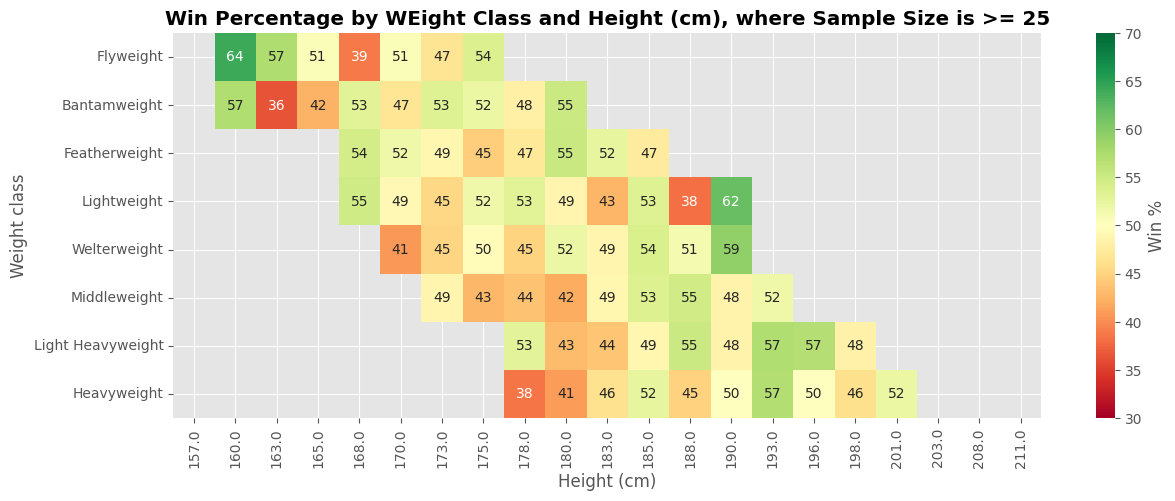

In [17]:
d = df.copy()
h = d['Height'].str.extract(r"(\d+)'\s*(\d+)").astype(float)
d['height_cm'] = ((h[0] * 12 + h[1]) * 2.54).round()
d['win'] = (d['result'] == 'win').astype(int)

order = ['Flyweight', 'Bantamweight', 'Featherweight', 'Lightweight', 'Welterweight',
         'Middleweight', 'Light Heavyweight', 'Heavyweight']
d = d[d['Weight class'].isin(order)]

win_pct = d.pivot_table(index='Weight class', columns='height_cm', values='win', aggfunc='mean').reindex(order) * 100
n = d.pivot_table(index='Weight class', columns='height_cm', values='win', aggfunc='count').reindex(order)

sample_size=25
plt.figure(figsize=(14, 5))
sns.heatmap(win_pct.where(n >= sample_size), cmap='RdYlGn', center=50, vmin=30, vmax=70,
            annot=True, fmt='.0f', cbar_kws={'label': 'Win %'})
plt.xlabel('Height (cm)')
plt.xticks(rotation=90)
plt.title(f'Win Percentage by WEight Class and Height (cm), where Sample Size is >= {sample_size}', fontweight='bold')
plt.show()

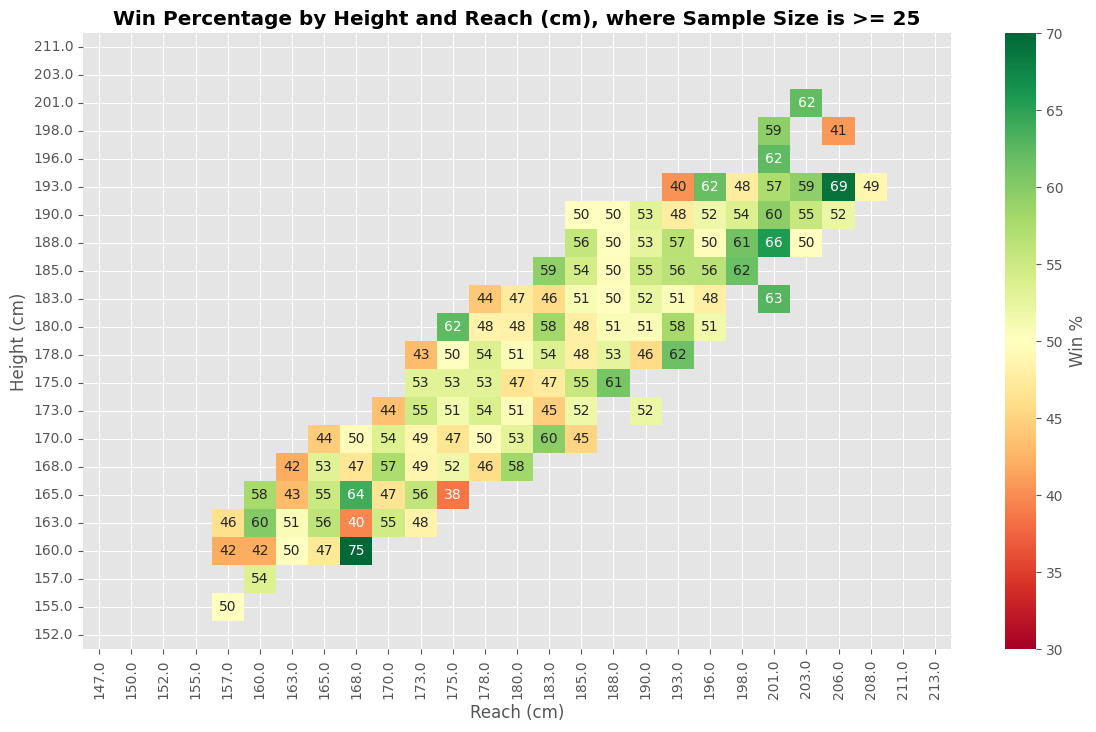

In [18]:
d = df.copy()
h = d['Height'].str.extract(r"(\d+)'\s*(\d+)").astype(float)
d['height_cm'] = ((h[0] * 12 + h[1]) * 2.54).round()
d['reach_cm'] = (d['Reach'].astype(str).str.extract(r'(\d+)')[0].astype(float) * 2.54).round()
d['win'] = (d['result'] == 'win').astype(int)
d = d.dropna(subset=['height_cm', 'reach_cm'])

win_pct = d.pivot_table(index='height_cm', columns='reach_cm', values='win', aggfunc='mean') * 100
n = d.pivot_table(index='height_cm', columns='reach_cm', values='win', aggfunc='count')

sample_size = 25
plt.figure(figsize=(14, 8))
ax = sns.heatmap(win_pct.where(n >= sample_size), cmap='RdYlGn', center=50, vmin=30, vmax=70,
                 annot=True, fmt='.0f', cbar_kws={'label': 'Win %'})
ax.invert_yaxis()
plt.xlabel('Reach (cm)')
plt.ylabel('Height (cm)')
plt.xticks(rotation=90)
plt.title(f'Win Percentage by Height and Reach (cm), where Sample Size is >= {sample_size}', fontweight='bold')
plt.show()

,height_cm,reach_cm,weight_kg,ape_index_cm,fighters
main_class,,,,,
Flyweight,167.4,170.6,57.0,3.1,138
Bantamweight,171.0,175.4,61.4,4.2,283
Featherweight,174.7,179.0,66.0,4.2,276
Lightweight,177.2,181.9,71.2,4.3,464
Welterweight,181.1,186.7,77.3,5.0,406
Middleweight,183.9,190.5,83.7,5.9,357
Light Heavyweight,186.9,193.2,92.8,5.5,201
Heavyweight,189.1,195.7,110.9,5.9,279
Women's Strawweight,161.3,162.1,52.5,1.0,112


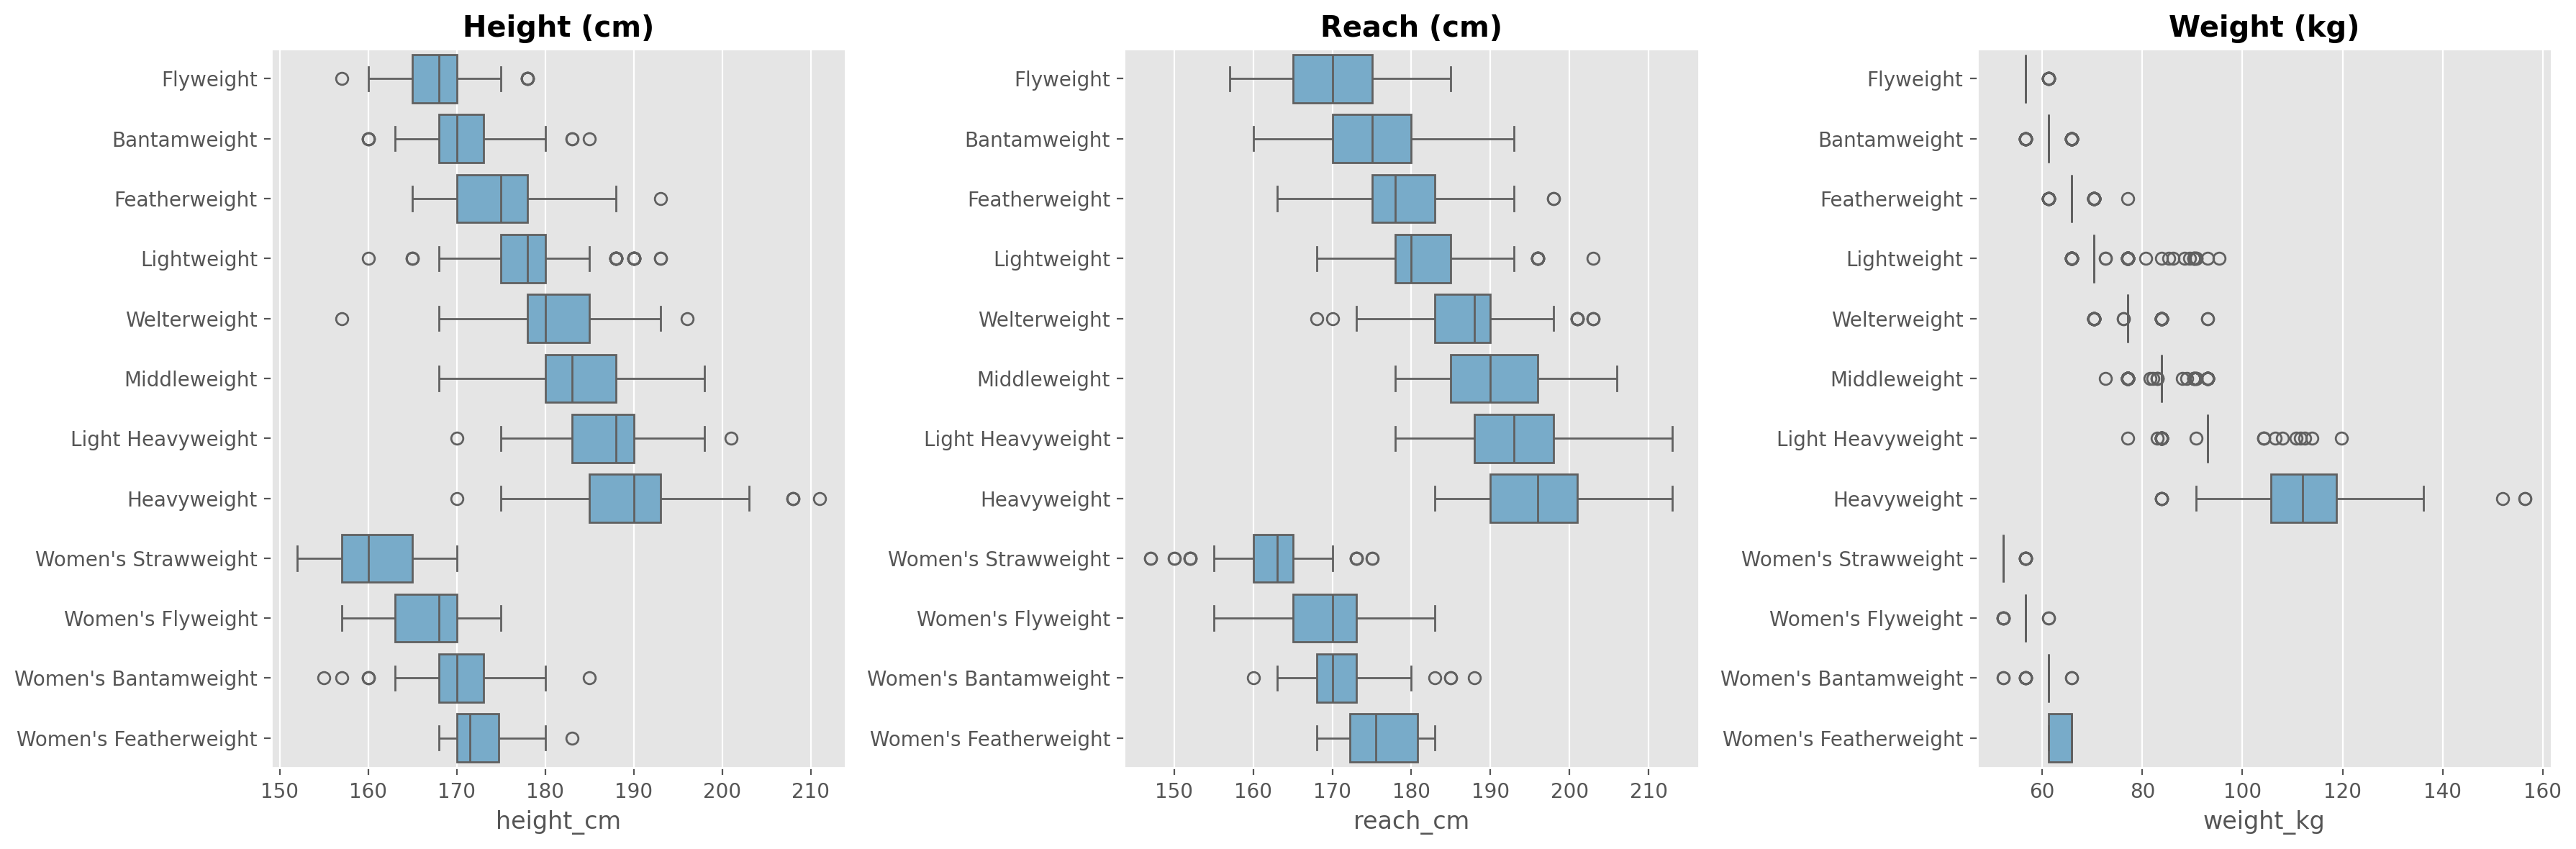

In [19]:

h = df['Height'].str.extract(r"(\d+)'\s*(\d+)").astype(float)
df['height_cm'] = ((h[0] * 12 + h[1]) * 2.54).round()
df['weight_kg'] = (df['Weight'].astype(str).str.extract(r'(\d+)')[0].astype(float) * 0.4536).round(1)
df['reach_cm'] = (df['Reach'].astype(str).str.extract(r'(\d+)')[0].astype(float) * 2.54).round()

men = ['Flyweight', 'Bantamweight', 'Featherweight', 'Lightweight', 'Welterweight',
       'Middleweight', 'Light Heavyweight', 'Heavyweight']
women = ["Women's Strawweight", "Women's Flyweight", "Women's Bantamweight", "Women's Featherweight"]
order = men + women
phys_cols = ['height_cm', 'reach_cm', 'weight_kg']

# one row per fighter
fighters = df.groupby('fighter').agg(
    height_cm=('height_cm', 'first'),
    reach_cm=('reach_cm', 'first'),
    weight_kg=('weight_kg', 'first'),
    main_class=('Weight class', lambda x: x.mode().iloc[0]),
).reset_index()
fighters['ape_index_cm'] = fighters['reach_cm'] - fighters['height_cm']

# summary table
summary = (fighters[fighters['main_class'].isin(order)]
           .groupby('main_class')[phys_cols + ['ape_index_cm']].mean().round(1)
           .reindex(order))
summary['fighters'] = fighters['main_class'].value_counts().reindex(order)
display(summary)

# box plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=200)
f = fighters[fighters['main_class'].isin(order)]
for ax, col, title in zip(axes, phys_cols, ['Height (cm)', 'Reach (cm)', 'Weight (kg)']):
    sns.boxplot(data=f, y='main_class', x=col, order=order, ax=ax, color='#6baed6')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

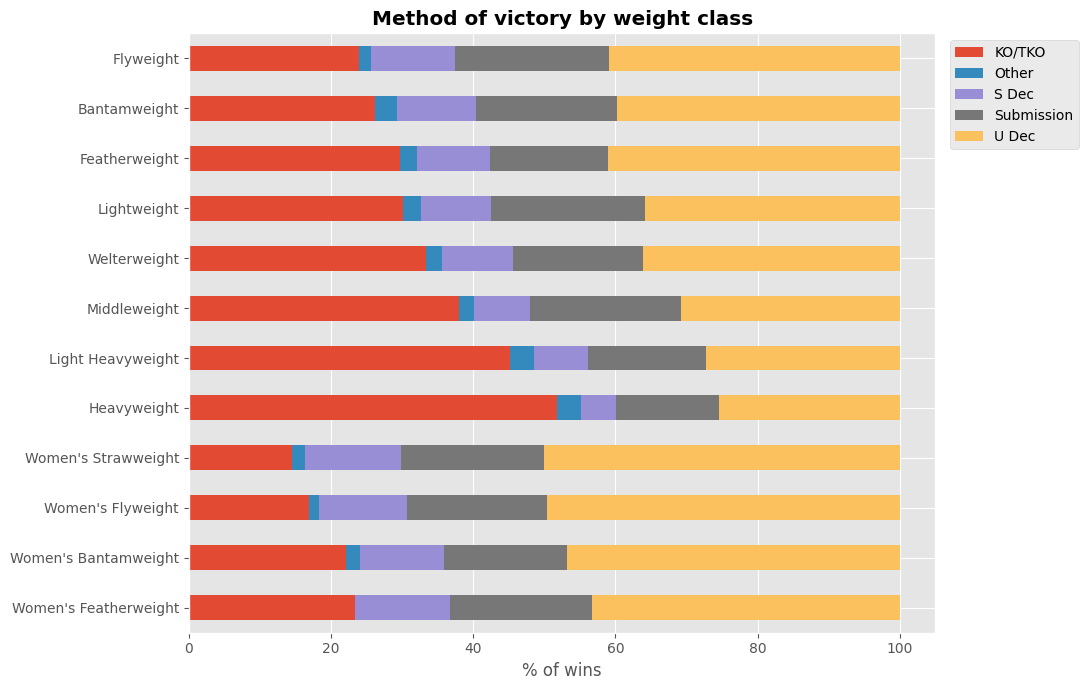

Method,KO/TKO,Other,S Dec,Submission,U Dec,Finish %
Weight class,,,,,,
Flyweight,24.0,1.6,11.9,21.6,40.9,45.6
Bantamweight,26.1,3.2,11.0,19.8,39.9,45.9
Featherweight,29.7,2.4,10.2,16.7,41.0,46.4
Lightweight,30.2,2.5,9.7,21.8,35.8,51.9
Welterweight,33.4,2.3,9.9,18.4,36.1,51.8
Middleweight,38.0,2.1,7.9,21.3,30.7,59.3
Light Heavyweight,45.2,3.4,7.6,16.6,27.3,61.7
Heavyweight,51.8,3.4,4.9,14.5,25.4,66.2
Women's Strawweight,14.6,1.9,13.5,20.1,50.0,34.7


In [23]:
wins_only = df[(df['result'] == 'win') & df['Weight class'].isin(order)]

methods = (pd.crosstab(wins_only['Weight class'], wins_only['Method'], normalize='index') * 100).reindex(order)
methods['Finish %'] = methods['KO/TKO'] + methods['Submission']

methods.drop(columns='Finish %').plot(kind='barh', stacked=True, figsize=(11, 7))
plt.gca().invert_yaxis()
plt.xlabel('% of wins')
plt.ylabel('')
plt.title('Method of victory by weight class', fontweight='bold')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

methods.round(1)